# NIFTY-50 stock histories: daily moves and trading activity

This project studies daily price moves and trading activity for five named stocks in the supplied NIFTY-50 archive: TCS, Infosys, Reliance, HDFC Bank and ITC. A common date window makes comparisons more consistent. It does not attempt to reproduce the NIFTY index or recommend investments.

## Data and scope

Source: [nifty50-stock-market-data](https://www.kaggle.com/datasets/rohanrao/nifty50-stock-market-data). This report uses the uploaded snapshot, not live data.

One row is one stock trading day. `Date` and `Symbol` identify the observation. `Open`, `High`, `Low`, `Close`, `Last`, `Prev Close` and `VWAP` are price fields in rupees. `Volume` counts traded shares. `Trades`, `Deliverable Volume`, `%Deliverble`, `Turnover` and `Series` provide trading metadata. The analysis uses `Close / Prev Close - 1` for the reported daily price move, not a dividend-adjusted total return. Turnover is not interpreted because its scale is not established here.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def data_path(filename):
    # Works after extracting this ZIP, or after attaching its data on Kaggle.
    for folder in (Path("data"), Path(".")):
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    kaggle = Path("/kaggle/input")
    matches = sorted(kaggle.rglob(filename)) if kaggle.exists() else []
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Place {filename} in data/, or attach its dataset on Kaggle. Found {len(matches)} Kaggle matches.")

In [2]:
names = ["TCS","INFY","RELIANCE","HDFCBANK","ITC"]
raw = pd.concat([pd.read_csv(data_path(name+".csv")).assign(source_stock=name) for name in names],ignore_index=True)
print(f"Raw data: {len(raw):,} trading rows, {raw.shape[1]} columns")
assert len(raw)>=150 and raw.shape[1]>=3
display(raw.head()); display(raw.isna().sum().to_frame("missing"))

Raw data: 25,363 trading rows, 16 columns


,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,%Deliverble,source_stock
0,2004-08-25,TCS,EQ,850.000,"1,198.700","1,198.700",979.000,985.000,987.950,"1,008.320",17116372,"1,725,876,095,745,000.000",NaN,"5,206,360.000",0.304,TCS
1,2004-08-26,TCS,EQ,987.950,992.000,997.000,975.300,976.850,979.000,985.650,5055400,"498,286,476,730,000.000",NaN,"1,294,899.000",0.256,TCS
2,2004-08-27,TCS,EQ,979.000,982.400,982.400,958.550,961.200,962.650,969.940,3830750,"371,558,603,080,000.000",NaN,"976,527.000",0.255,TCS
3,2004-08-30,TCS,EQ,962.650,969.900,990.000,965.000,986.400,986.750,982.650,3058151,"300,510,633,990,000.000",NaN,"701,664.000",0.229,TCS
4,2004-08-31,TCS,EQ,986.750,986.500,990.000,976.000,987.800,988.100,982.180,2649332,"260,213,265,065,000.000",NaN,"695,234.000",0.262,TCS


,missing
Date,0
Symbol,0
Series,0
Prev Close,0
Open,0
High,0
Low,0
Last,0
Close,0
VWAP,0


## Cleaning and choosing comparable dates

`concat()` combines the five stock files; `assign()` retains a stable stock label even if the exchange symbol changed. Invalid prices and volumes are flagged rather than silently included. `pivot()` aligns stock observations by date and `dropna()` keeps only dates with all five daily moves. This avoids comparing stocks over different periods. Large moves are retained and listed for review because corporate actions and data issues can look like market shocks.

Invalid rows excluded: 0; duplicate stock-date keys: 0
Common window: 2004-08-25 to 2021-04-30, 4,139 shared trading dates


daily_move_pct                             Volume                \
                      count  mean median     min    max  count          mean   
source_stock                                                                   
HDFCBANK               4139 0.074  0.036 -79.920 16.300   4139 2,648,406.774   
INFY                   4139 0.034  0.049 -51.111 16.785   4139 3,184,195.762   
ITC                    4139 0.024  0.026 -92.734 11.162   4139 9,054,271.067   
RELIANCE               4139 0.068  0.055 -51.531 21.369   4139 5,707,891.084   
TCS                    4139 0.064  0.047 -51.126 16.229   4139 1,676,761.950   

                                             intraday_range_pct               \
                    median    min        max              count  mean median   
source_stock                                                                   
HDFCBANK     1,342,060.000   9325  100564990               4139 2.689  2.136   
INFY         1,596,460.000  17453   90433393               4139 2.528  2.105   
ITC          6,504,976.000  31029  149479681               4139 2.688  2.214   
RELIANCE     4,198,139.000  52820   65230894               4139 2.742  2.256   
TCS          1,227,748.000  18345   44033577               4139 2.780  2.273   

                           
               min    max  
source_stock               
HDFCBANK     0.381 28.621  
INFY         0.428 20.288  
ITC          0.438 23.077  
RELIANCE     0.311 25.392  
TCS          0.527 32.527

,Date,source_stock,Close,Prev Close,daily_move_pct
17632,2011-07-14,HDFCBANK,505.950,"2,519.700",-79.920
19656,2019-09-19,HDFCBANK,"1,101.050","2,187.750",-49.672
5779,2006-07-13,INFY,"1,681.950","3,385.650",-50.321
7456,2013-04-12,INFY,"2,296.650","2,916.700",-21.259
7858,2014-12-02,INFY,"2,126.600","4,349.850",-51.111
7990,2015-06-15,INFY,990.450,"1,975.050",-49.852
8790,2018-09-04,INFY,737.150,"1,434.250",-48.604
21495,2005-09-21,ITC,140.200,"1,929.600",-92.734
22699,2010-08-03,ITC,154.400,312.800,-50.639
24168,2016-07-01,ITC,252.350,368.400,-31.501


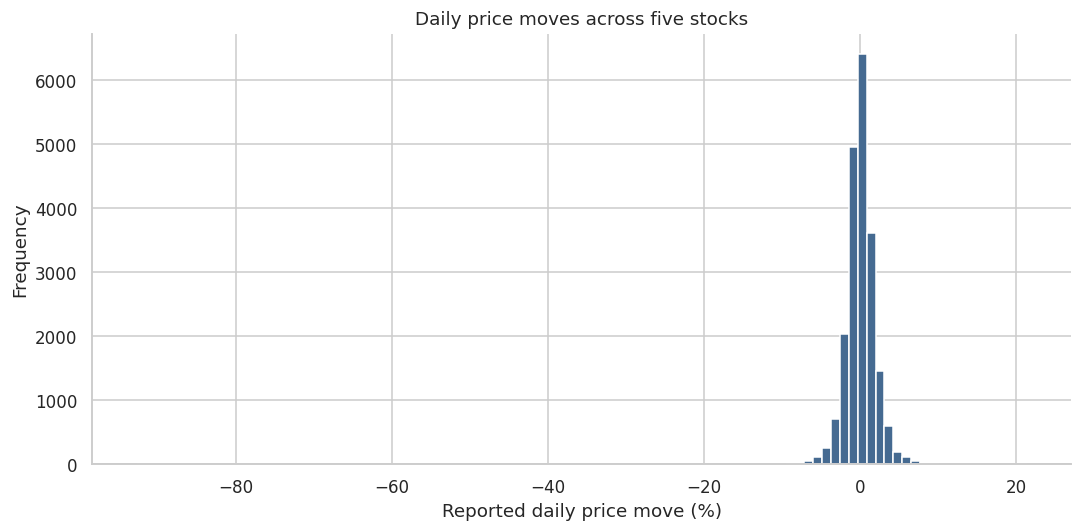

In [3]:
df = raw.drop_duplicates().copy()
df["Date"] = pd.to_datetime(df.Date,errors="coerce")
for col in ["Open","High","Low","Close","Prev Close","Volume"]:
    df[col] = pd.to_numeric(df[col],errors="coerce")
bad = df.Date.isna() | (df[["Open","High","Low","Close","Prev Close"]]<=0).any(axis=1) | df.Volume.lt(0) | df.High.lt(df.Low)
print(f"Invalid rows excluded: {bad.sum()}; duplicate stock-date keys: {df.duplicated(['source_stock','Date']).sum()}")
df = df.loc[~bad].sort_values(["source_stock","Date"]).copy()
df["daily_move_pct"] = (df.Close/df["Prev Close"]-1)*100
df["intraday_range_pct"] = (df.High-df.Low)/df.Open*100
moves = df.pivot(index="Date",columns="source_stock",values="daily_move_pct").dropna()
common = df[df.Date.isin(moves.index)].copy()
print(f"Common window: {moves.index.min().date()} to {moves.index.max().date()}, {len(moves):,} shared trading dates")
display(common.groupby("source_stock")[["daily_move_pct","Volume","intraday_range_pct"]].agg(["count","mean","median","min","max"]))
display(common.loc[common.daily_move_pct.abs()>20,["Date","source_stock","Close","Prev Close","daily_move_pct"]].head(20))
common.daily_move_pct.plot.hist(bins=100,color="#456a91")
plt.xlabel("Reported daily price move (%)"); plt.title("Daily price moves across five stocks"); plt.tight_layout(); plt.show()

## 1. Which stock has the widest typical intraday range?

The range is `(High - Low) / Open`, expressed as a percentage. Grouped medians compare a typical trading day without comparing rupee prices directly. This is a range measure, not a realised trading profit.

,count,median,mean
source_stock,,,
TCS,4139,2.273,2.780
RELIANCE,4139,2.256,2.742
ITC,4139,2.214,2.688
HDFCBANK,4139,2.136,2.689
INFY,4139,2.105,2.528


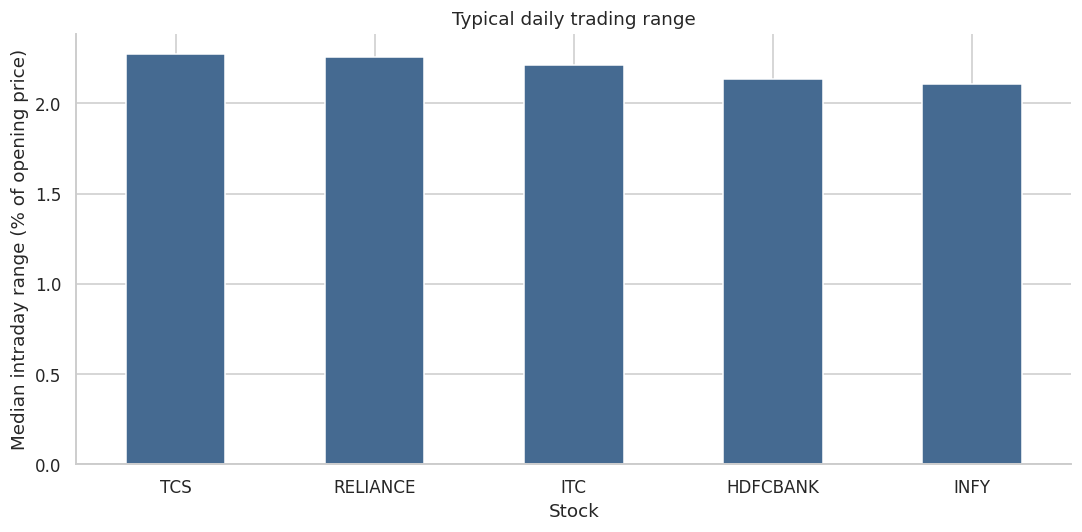

In [4]:
ranges = common.groupby("source_stock").intraday_range_pct.agg(["count","median","mean"]).sort_values("median",ascending=False)
display(ranges)
ranges["median"].plot.bar(color="#456a91",rot=0)
plt.ylabel("Median intraday range (% of opening price)"); plt.xlabel("Stock"); plt.title("Typical daily trading range")
plt.tight_layout(); plt.show()

**Answer.** TCS has the highest median intraday range at 2.27% of its opening price. The comparison uses the same 4,139 trading dates for each stock.

## 2. Which stock shows the most variable daily price moves?

`std()` measures the spread of daily moves. Multiplying by `sqrt(252)` gives a conventional annualised scale, assuming 252 trading days; it does not forecast next year’s volatility. The raw and a sensitivity calculation excluding moves above 20% are both shown, without deleting those events from the main dataset.

,daily_std_pct,annualised_std_pct,over_20pct_days,sensitivity_annualised_pct
source_stock,,,,
ITC,2.490,39.522,3,28.658
INFY,2.475,39.290,5,30.119
RELIANCE,2.402,38.130,4,32.734
TCS,2.388,37.900,3,31.133
HDFCBANK,2.384,37.837,2,29.857


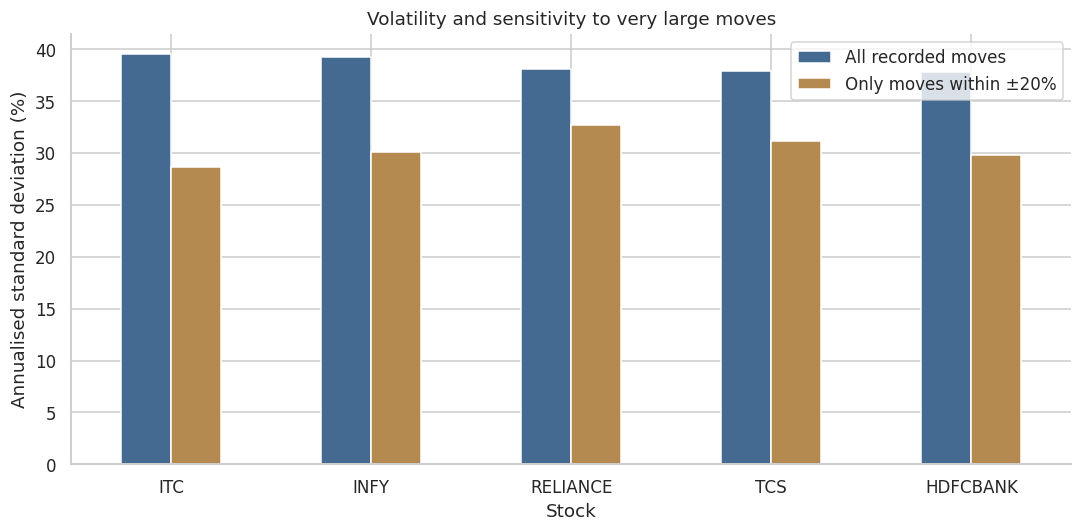

In [5]:
volatility = pd.DataFrame({"daily_std_pct":moves.std(),"annualised_std_pct":moves.std()*np.sqrt(252),"over_20pct_days":moves.abs().gt(20).sum(),"sensitivity_annualised_pct":moves.where(moves.abs()<=20).std()*np.sqrt(252)}).sort_values("annualised_std_pct",ascending=False)
display(volatility)
volatility[["annualised_std_pct","sensitivity_annualised_pct"]].plot.bar(rot=0,color=["#456a91","#b48a51"])
plt.ylabel("Annualised standard deviation (%)"); plt.xlabel("Stock"); plt.title("Volatility and sensitivity to very large moves")
plt.legend(["All recorded moves","Only moves within ±20%"]); plt.tight_layout(); plt.show()

**Answer.** ITC has the highest standard deviation on the full recorded series (39.52% annualised). The adjacent sensitivity column shows how much unusually large observations affect the estimate. This threshold check is not a substitute for verified corporate-action adjustments.

## 3. How often do the five stocks move in the same direction and magnitude?

`corr()` computes Pearson correlations on the aligned daily moves. A positive coefficient indicates that larger moves often occur together. Using shared dates avoids correlations based on different time windows.

source_stock,HDFCBANK,INFY,ITC,RELIANCE,TCS
source_stock,,,,,
HDFCBANK,1.000,0.219,0.214,0.339,0.220
INFY,0.219,1.000,0.141,0.238,0.382
ITC,0.214,0.141,1.000,0.214,0.183
RELIANCE,0.339,0.238,0.214,1.000,0.288
TCS,0.220,0.382,0.183,0.288,1.000


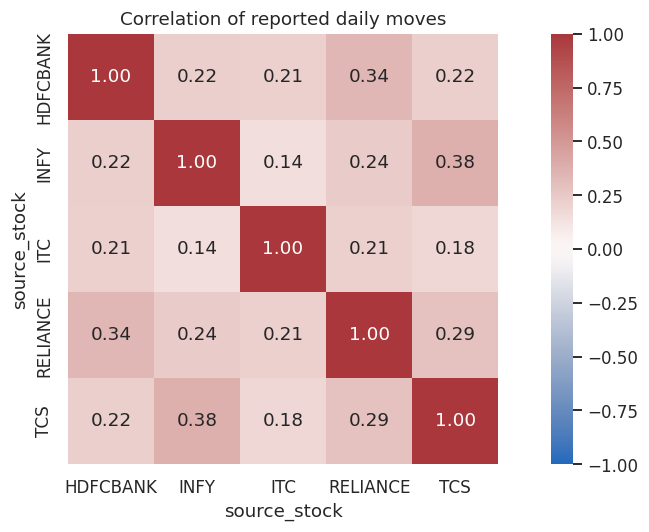

In [6]:
correlations = moves.corr()
display(correlations)
sns.heatmap(correlations,annot=True,fmt=".2f",vmin=-1,vmax=1,center=0,cmap="vlag",square=True)
plt.title("Correlation of reported daily moves"); plt.tight_layout(); plt.show()
upper = correlations.where(np.triu(np.ones(correlations.shape),k=1).astype(bool)).stack()

**Answer.** The highest pairwise correlation is between INFY and TCS (0.382). Correlation is historical and does not establish that one stock drives the other or that the relationship will stay constant.

## 4. Is heavier trading associated with larger price moves?

Volume is divided by its stock’s median, creating a relative-volume measure. `abs()` treats upward and downward moves symmetrically. A Spearman correlation compares their ordering without assuming a linear relationship. The scatter plot uses a fixed sample only to keep the figure readable; the table uses all shared-date observations.

,spearman_rho
HDFCBANK,0.084
INFY,0.178
ITC,0.214
RELIANCE,0.290
TCS,0.233


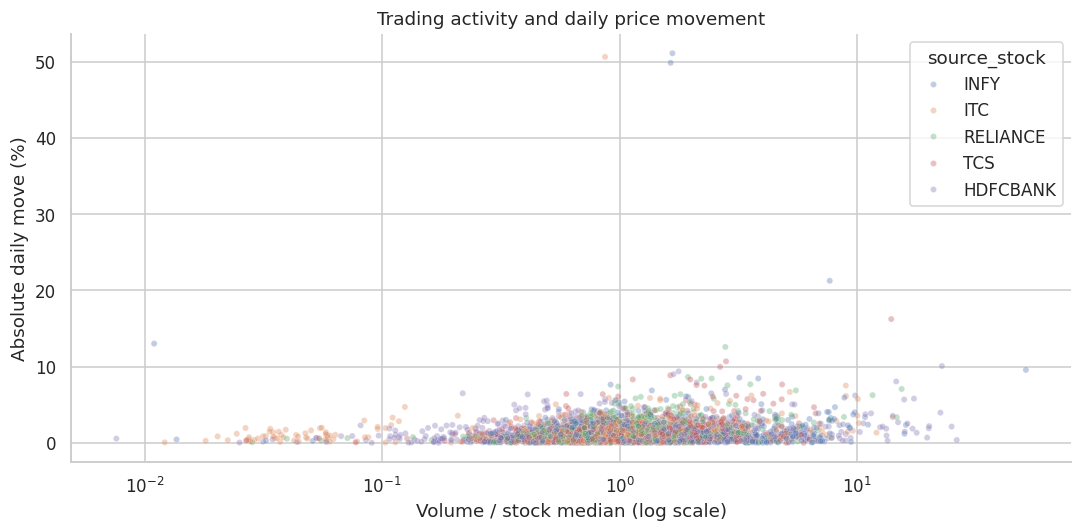

In [7]:
common["relative_volume"] = common.Volume/common.groupby("source_stock").Volume.transform("median")
common["absolute_move_pct"] = common.daily_move_pct.abs()
association = pd.Series({name:g.relative_volume.corr(g.absolute_move_pct,method="spearman") for name,g in common.groupby("source_stock")},name="spearman_rho")
display(association.to_frame())
plot_data = common.sample(min(4000,len(common)),random_state=17)
sns.scatterplot(data=plot_data,x="relative_volume",y="absolute_move_pct",hue="source_stock",alpha=.35,s=16)
plt.xscale("log"); plt.xlabel("Volume / stock median (log scale)"); plt.ylabel("Absolute daily move (%)")
plt.title("Trading activity and daily price movement"); plt.tight_layout(); plt.show()

**Answer.** The strongest positive rank association is for RELIANCE (0.290). Volume and price changes are observed on the same day, so this analysis cannot establish which occurred first or whether either predicts future moves.

## 5. Did volatility change across calendar years?

Yearly standard deviations are calculated only for stock-years with at least 150 shared observations. This excludes partial years with too few trading days. A yearly heatmap makes changes in market conditions easier to see than a single whole-period average.

source_stock,HDFCBANK,INFY,ITC,RELIANCE,TCS
year,,,,,
2005,29.409,26.148,96.991,24.691,27.754
2006,34.272,59.415,34.866,42.914,60.661
2007,39.264,31.286,32.532,32.269,29.925
2008,57.459,48.801,42.536,59.698,57.428
2009,37.676,38.062,36.344,72.411,68.770
2010,22.779,21.223,55.542,24.576,26.386
2011,85.306,29.731,24.184,31.060,31.495
2012,20.010,26.651,22.049,25.294,25.751
2013,29.560,35.493,26.213,27.303,25.044


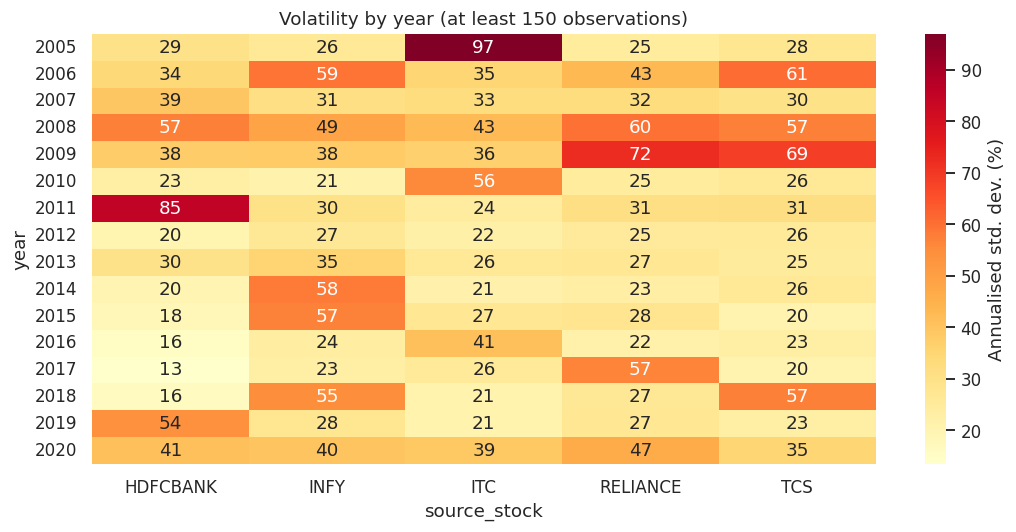

In [8]:
common["year"] = common.Date.dt.year
annual = common.groupby(["year","source_stock"]).daily_move_pct.agg(["count","std"])
annual["annualised_pct"] = (annual["std"]*np.sqrt(252)).where(annual["count"]>=150)
annual_grid = annual.annualised_pct.unstack().dropna(how="all")
display(annual_grid)
sns.heatmap(annual_grid,annot=True,fmt=".0f",cmap="YlOrRd",cbar_kws={"label":"Annualised std. dev. (%)"})
plt.title("Volatility by year (at least 150 observations)"); plt.tight_layout(); plt.show()
highest = annual_grid.stack().idxmax()

**Answer.** The highest stock-year estimate is ITC in 2005, at 96.99% annualised. Volatility varies across years, so the whole-period ranking hides substantial changes over time.

## Conclusion

Across 4,139 shared trading dates, TCS has the largest median intraday range at 2.27%. ITC has the highest full-series annualised standard deviation at 39.52%; the sensitivity table shows why unusually large moves need investigation before interpreting this as ordinary trading risk.

The five stocks differ in daily range, volatility and their association with trading volume. Shared trading dates make the comparisons more consistent, while yearly estimates show why risk cannot be summarised fully by one historical number.